## Praktikum 1
##### Einführung in Jupyter-Notebooks und Grundlagen der Bildverarbeitung

Jupyter-Notebooks sind einzelne Sammlungen von (in diesem Fall Python-)`Code`- und ***Markdown***-Abschnitten. Früher hießen Jupyter-Notebooks *IPython-Notebooks* (deshalb die Dateiendung *.ipynb*).

Markdown ist eine Markup-Sprache wie HTML (welche im übrigen auch unterstützt wird) und kann **Text** gestylet darstellen. Auch Links und Bilder können eingebunden werden. Sie können über die Taskleiste oben neue Felder hinzufügen. Codeblöcke können einzeln laufen, was die benötigte Zeit drastisch reduzieren kann (beachten Sie dabei die Tastenkombination Strg+Enter). Beispielsweise werden wir später KI-Modelle trainieren, was etwas länger braucht. Aber sobald wir das Modell einmal trainiert und serialisiert (= auf der Festplatte gespeichert) haben, müssen wir das Modell nicht jedes Mal neu trainieren, wenn wir es benutzen wollen, ohne dafür separaten Code zu schreiben.

[Weitere Hinweise zum Benutzen von Jupyter-Notebooks](https://code.visualstudio.com/docs/datascience/jupyter-notebooks)

[Markdown-Syntax](https://www.markdownguide.org/basic-syntax/)

<div style="padding: 10px; border-left: 5px solid #B777FA; background-color: #5C18FA; border-radius: 4px">
  🐍 Bitte nutzen Sie die virtuelle Umgebung: <b>DLACV_2526</b>
</div>

In [1]:
# imports
import numpy as np
import cv2
from matplotlib import pyplot as plt

#### Teil 1: Grundlagen

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.1:</b><br>
  • Importieren Sie <code>image.jpg</code>.<br>
  • Zeigen Sie das Bild richtig im Jupyter-Notebook an.<br>
  • Geben Sie die Höhe und Breite des Bildes in Pixeln und die Anzahl Kanäle des Bildes an.<br>
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Überprüfen Sie das Format und die Kanäle, in denen das Bild eingelesen wird.<br>Sollte das Bild nicht richtig aussehen, ist möglicherweise die Reihenfolge der Farbkanäle falsch.
</div>

Image Dimensions: (2335, 4151)


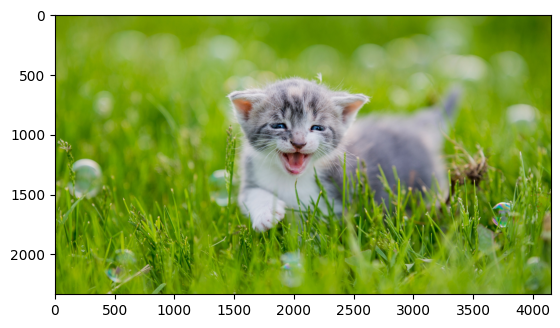

In [2]:
# Bild importieren
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
img_rgb = cv2.imread('image.jpg', cv2.IMREAD_COLOR)

img_rgb = img_rgb[::,::,::-1]

# Bild anzeigen
plt.imshow(img, cmap = 'gray')
plt.imshow(img_rgb)

# Dimensionen zeigen
print("Image Dimensions: "+ str(img.shape))

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.2:</b><br>
  • Geben Sie die einzelnen Kanäle (<b><span style="color: red">R</span>,<span style="color: green">G</span>,<span style="color: cyan">B</span></b>) des Bildes als eigene Bilder aus.<br>
   • Setzen Sie die Colormaps so, dass im Ergebnisplot die obere Zeile als Grauwertbild und die untere Zeile mit einer Colormap der entsprechenden Farbe angezeigt wird.
</div>

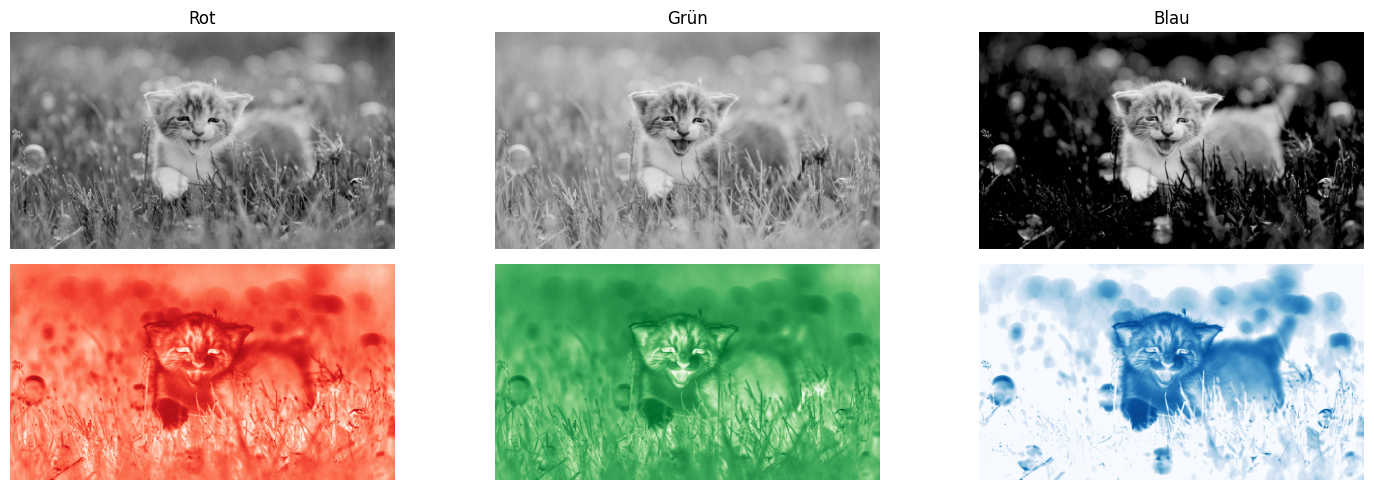

In [166]:
# Einzelne Kanäle
img_r = img_rgb[:,:,0]
img_g = img_rgb[:,:,1]
img_b = img_rgb[:,:,2]

# Zeige 3 Bilder nebeneinander an
fig, axes = plt.subplots(2, 3, figsize=(15, 5))
axes[0, 0].imshow(img_r, cmap='gray')
axes[0, 0].axis('off')
axes[0, 0].set_title('Rot')

axes[1, 0].imshow(img_r, cmap='Reds')
axes[1, 0].axis('off')

axes[0, 1].imshow(img_g, cmap='gray')
axes[0, 1].axis('off')
axes[0, 1].set_title('Grün')

axes[1, 1].imshow(img_g, cmap='Greens')
axes[1, 1].axis('off')

axes[0, 2].imshow(img_b, cmap='gray')
axes[0, 2].axis('off')
axes[0, 2].set_title('Blau')

axes[1, 2].imshow(img_b, cmap='Blues')
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.3:</b><br>
  Wandeln Sie das RGB-Bild in ein Grauwertbild um:<br>
  • Mit Hilfe der entsprechenden <b>OpenCV-Funktion</b>.<br>
  • Mit Hilfe der <b>in der Vorlesung vorgestellten Linearkombination</b>.<br>
  • Die beiden Grauwertbilder sollen <b>gleich</b> sein <i>(d.h. das Unterschiede-Bild soll komplett schwarz sein)</i>.<br>
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis 1:</b></i> Beachten Sie die unterschiedlichen Datentypen, falls <code>cv2.absdiff</code> einen Fehler wirft. Dazu kann die Funktion <code>astype()</code> hilfreich sein.<br>
💡 <i><b>Hinweis 2:</b></i> Grauwertbilder beinhalten <code>uint8</code>-Werte, also im Bereich von [0-255].<br>Wenn Sie das jetzt mit einer Fließkommazahl multiplizieren, bedenken Sie, wie der dazugehörige <code>uint8</code>-Wert berechnet wird.
</div>

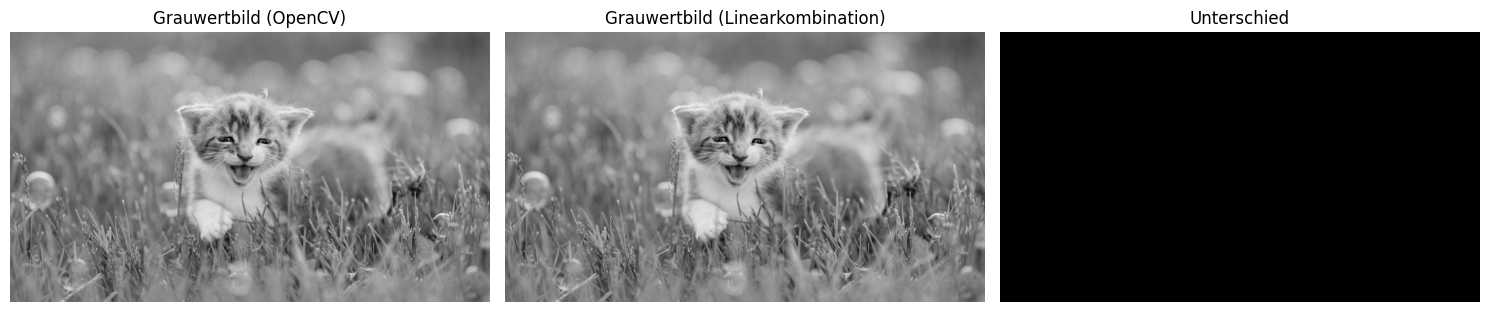

In [173]:
# OpenCV
img_gray_opencv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

# Linearkombination
img_gray_self = 0.299 * img_r.astype(np.float32) + 0.587 * img_g.astype(np.float32) + 0.114 * img_b.astype(np.float32)
img_gray_self = np.clip(np.round(img_gray_self), 0, 255).astype(np.uint8)

# Unterschied
img_diff = cv2.absdiff(img_gray_opencv, img_gray_self)

# Anzeigen
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_gray_opencv, cmap='gray')
axes[0].axis('off')
axes[0].set_title('Grauwertbild (OpenCV)')

axes[1].imshow(img_gray_self, cmap='gray')
axes[1].axis('off')
axes[1].set_title('Grauwertbild (Linearkombination)')

axes[2].imshow(img_diff, cmap='gray')
axes[2].axis('off')
axes[2].set_title('Unterschied')

plt.tight_layout()
plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.4:</b><br>
  Wandeln Sie das Grauwertbild in ein Binärbild um:<br>
  • Mit einem <b>eigenen Threshold</b> <i>(z.B. 128)</i>.<br>
  • Mit dem <b>Algorithmus nach Otsu</b>.<br>
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Das Unterschied-Bild sollte hier <b>nicht</b> komplett schwarz sein.
</div>

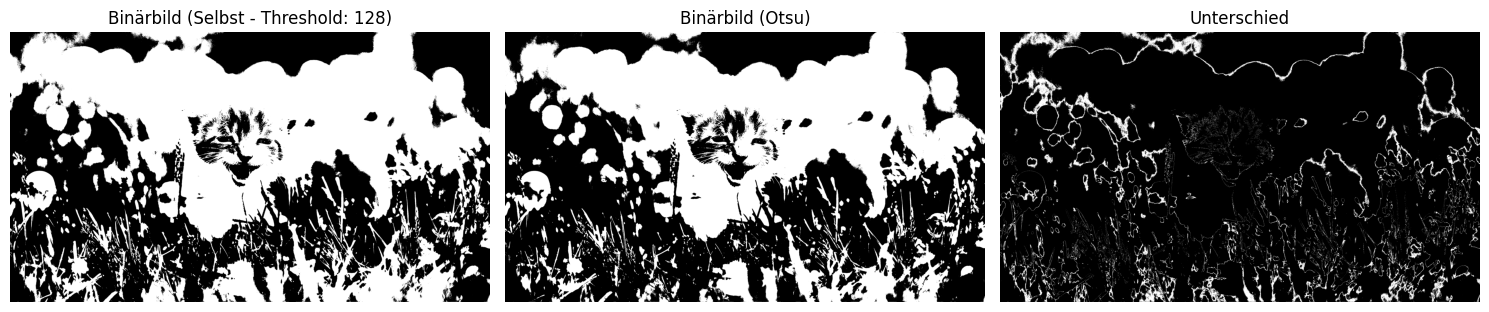

In [174]:
# Selbst
threshold = 128
_, img_bin_threshold = cv2.threshold(img_gray_opencv, threshold, 255, cv2.THRESH_BINARY)

# Otsu
_, img_bin_otsu = cv2.threshold(img_gray_opencv, 0, 255, cv2.THRESH_BINARY +cv2.THRESH_OTSU)

# Unterschied
img_diff = cv2.absdiff(img_bin_threshold, img_bin_otsu)

# Anzeigen
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_bin_threshold, cmap='gray')
axes[0].axis('off')
axes[0].set_title(f'Binärbild (Selbst - Threshold: {threshold})')

axes[1].imshow(img_bin_otsu, cmap='gray')
axes[1].axis('off')
axes[1].set_title('Binärbild (Otsu)')

axes[2].imshow(img_diff, cmap='gray')
axes[2].axis('off')
axes[2].set_title('Unterschied')

plt.tight_layout()
plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.5:</b><br>
  • Nennen Sie drei weitere Farbsysteme (außer RGB) aus der Vorlesung und ob diese jeweils wahrnehmungsangepasst sind oder nicht.<br>
  • Nennen Sie die drei in der Vorlesung vorgestellten Distanzmaße zwischen 2 Pixeln.<br>
</div>

**Farbsysteme**
1) HSV ja
2) YUV nein
3) CMY nein

**Distanzmaße**
1) euklidisch
2) Manhatten
3) Schachbrett

#### Teil 2: Pixelbasierte Algorithmen zur Bildverbesserung

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.1:</b><br>
  • Importieren Sie <code>pout.tif</code> als <b>Grauwertbild</b>.<br>
  • Zeigen Sie das Bild richtig im Jupyter-Notebook an.<br>
  • Geben Sie die Höhe und Breite des Bildes in Pixeln an.<br>
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Überprüfen Sie das Format und die Kanäle, in denen das Bild eingelesen wird, sollte das Bild nicht richtig aussehen.<br>
</div>

(291, 240)


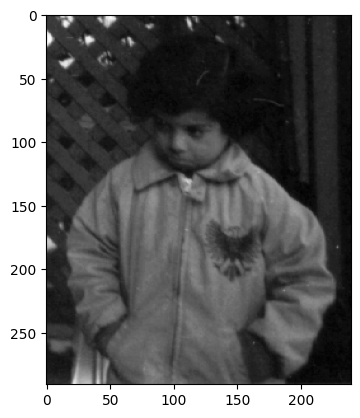

In [156]:
# Bild importieren
img = cv2.imread("pout.tif", cv2.IMREAD_GRAYSCALE)

# Bild anzeigen
plt.imshow(img, cmap="gray")

# Dimensionen zeigen
print(img.shape)

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.2:</b><br>
  Berechnen Sie zu dem Bild:<br>
  • Das <b>Histogramm h(g)</b>.<br>
  • Das <b>normierte Histogramm p(g)</b>.<br>
  • Das <b>kumulative Histogramm H(g)</b>.<br>
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Histogramme aus den vorigen Schritten können bei den folgenden Histogrammen hilfreich sein.<br>
</div>

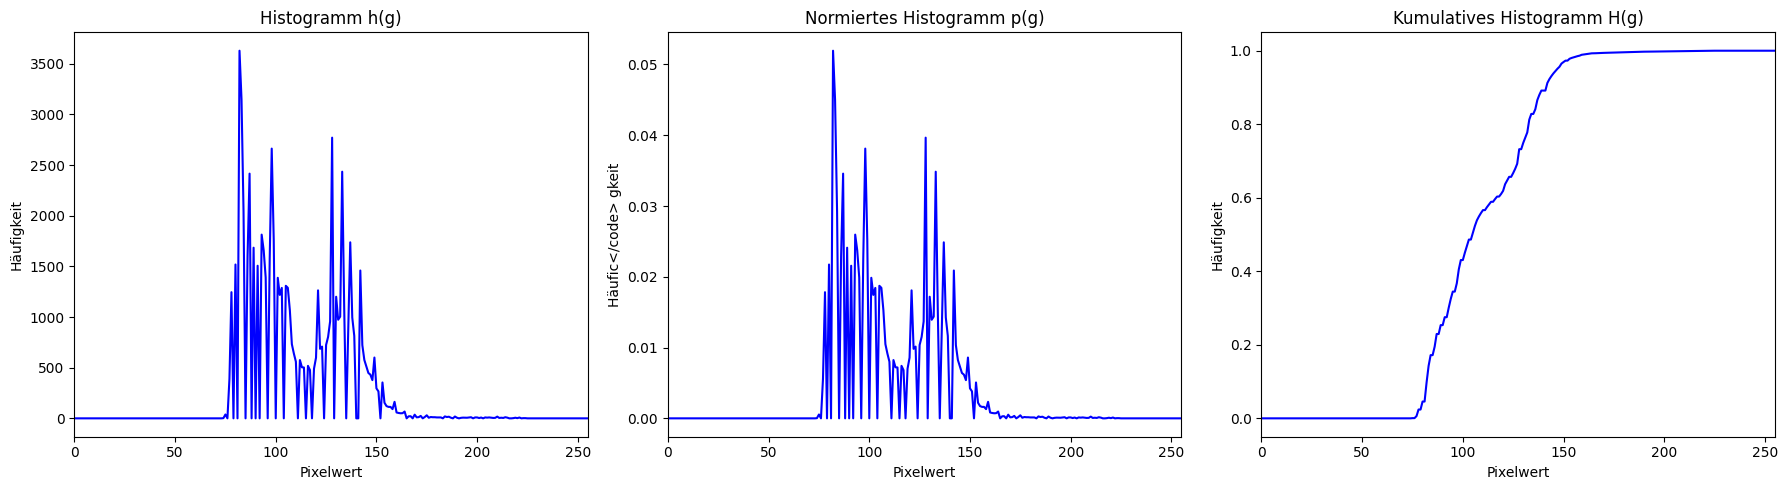

In [157]:
# Histogramm
hist = cv2.calcHist([img],[0],None, [256],[0,256])

# Normiertes Histogramm
hist_norm = cv2.calcHist([img],[0],None,[256],[0,256])
cv2.normalize(hist_norm,hist_norm,norm_type=cv2.NORM_L1)

# Kumulatives Histogramm
hist_cumu = np.cumsum(hist_norm)

# Anzeigen
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(hist, color='blue')
axes[0].set_xlim([0, 255])
axes[0].set_title('Histogramm h(g)')
axes[0].set_xlabel('Pixelwert')
axes[0].set_ylabel('Häufigkeit')

axes[1].plot(hist_norm, color='blue')
axes[1].set_xlim([0, 255])
axes[1].set_title('Normiertes Histogramm p(g)')
axes[1].set_xlabel('Pixelwert')
axes[1].set_ylabel('Häufic</code> gkeit')

axes[2].plot(hist_cumu, color='blue')
axes[2].set_xlim([0, 255])
axes[2].set_title('Kumulatives Histogramm H(g)')
axes[2].set_xlabel('Pixelwert')
axes[2].set_ylabel('Häufigkeit')

plt.tight_layout()
plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.3:</b><br>
  Berechnen Sie zu dem Bild:<br>
  • Den <b>Mittelwert</b>.<br>
  • Die <b>Varianz</b>.<br>
  • Die <b>Standardabweichung</b>.<br>
  • Den <b>globalen Kontrast</b>.<br>
</div>

In [158]:
# Mittelwert
mean = img.mean()

# Varianz
variance = img.var()

# Standardabweichung
std = img.std()

# Globaler Kontrast
g_min, g_max = 0,0
found_non_zero = False
for idx,i in enumerate(hist):
    if i != 0:
        found_non_zero = True
        g_max = idx
    if not found_non_zero:
        g_min = idx
    
global_contrast =  g_max - g_min

print(f'Mittelwert: {mean}\nVarianz: {variance}\nStandardabweichung: {std}\nGlobaler Kontrast: {global_contrast}')

Mittelwert: 110.3036941580756
Varianz: 537.3570252993587
Standardabweichung: 23.180962561967927
Globaler Kontrast: 151


<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.4:</b><br>
  • Wenden Sie eine <b>lineare Grauwertspreizung (Histogrammstretching)</b> auf das Bild an.<br>
  • Berechnen Sie anschließend das dazugehörige <b>Histogramm h(g)</b>.<br>
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Überlegen Sie genau, in welchen Wertebereich Sie abbilden möchten.<br>
</div>

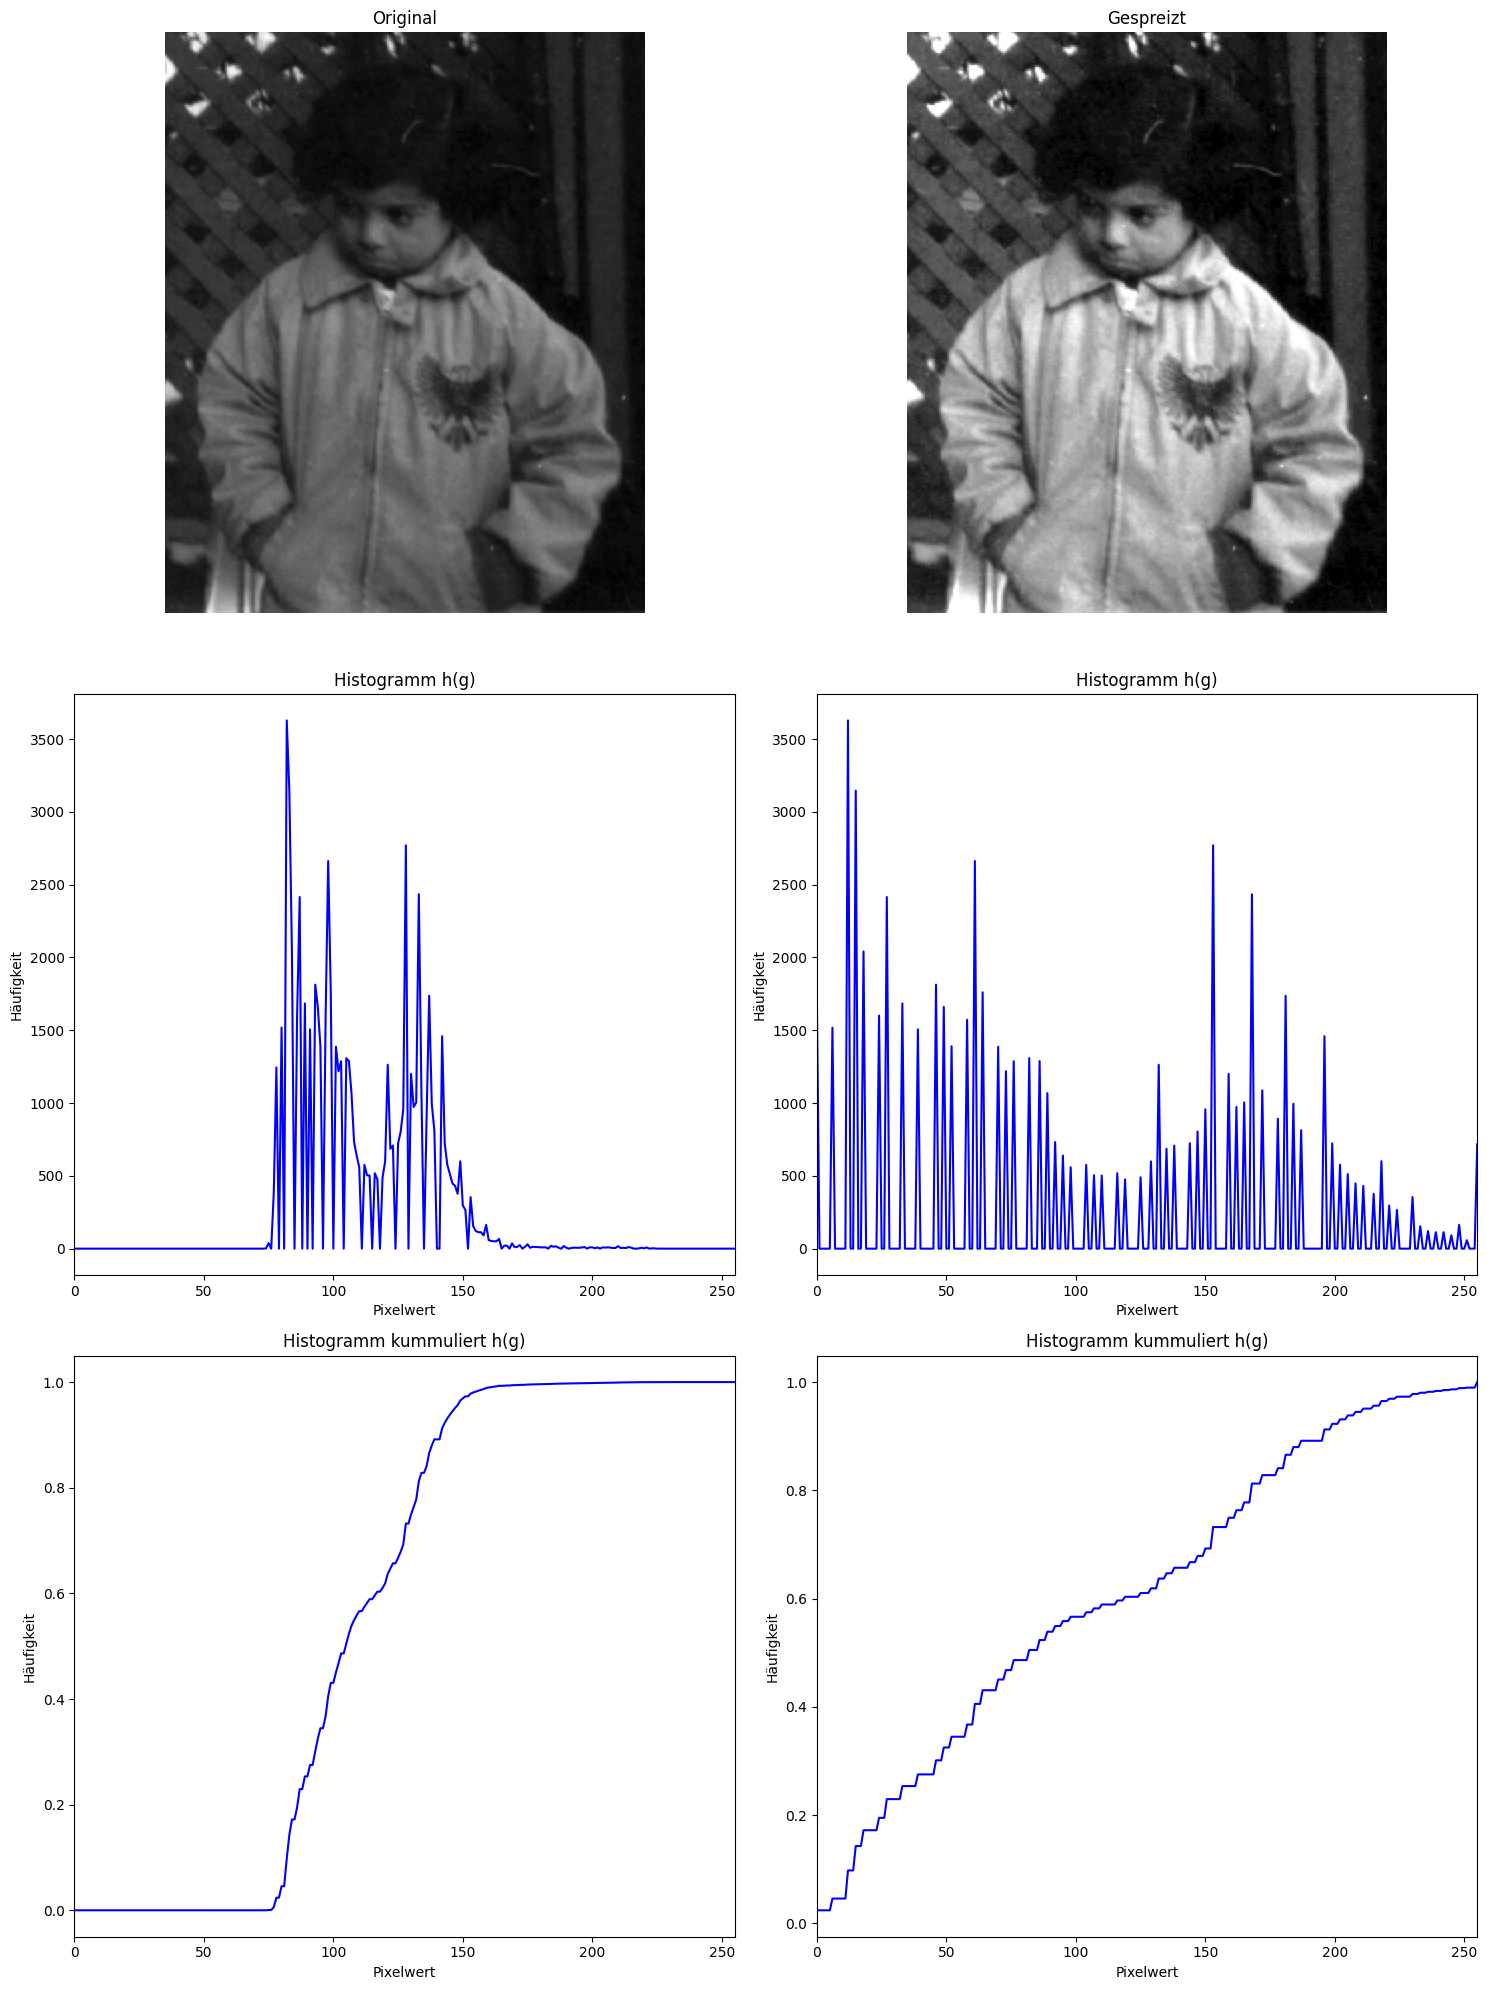

In [159]:
nonzero_pixels = img[img != 0]

# Grenzen bestimmen
low = np.percentile(nonzero_pixels, 1) # 1%
high = np.percentile(nonzero_pixels, 99) # 99%

# Lineare Spreizung
f = (img.astype(np.float32) - low) / (high - low) * 255
img_stretched = np.clip(f, 0, 255).astype(np.uint8)
hist_stretched = cv2.calcHist([img_stretched],[0],None,[256],[0,256]) 

# Anzeigen
fig, axes = plt.subplots(3, 2, figsize=(15, 20))

axes[0, 0].imshow(img, cmap='gray')
axes[0, 0].axis('off')
axes[0, 0].set_title('Original')

axes[1, 0].plot(hist, color='blue')
axes[1, 0].set_xlim([0, 255])
axes[1, 0].set_title('Histogramm h(g)')
axes[1, 0].set_xlabel('Pixelwert')
axes[1, 0].set_ylabel('Häufigkeit')

axes[0, 1].imshow(img_stretched, cmap='gray')
axes[0, 1].axis('off')
axes[0, 1].set_title('Gespreizt')

axes[1, 1].plot(hist_stretched, color='blue')
axes[1, 1].set_xlim([0, 255])
axes[1, 1].set_title('Histogramm h(g)')
axes[1, 1].set_xlabel('Pixelwert')
axes[1, 1].set_ylabel('Häufigkeit')

cv2.normalize(hist_stretched,hist_stretched,norm_type=cv2.NORM_L1)

axes[2,1].plot(hist_stretched.cumsum(), color="blue")
axes[2, 1].set_xlim([0, 255])
axes[2, 1].set_title('Histogramm kummuliert h(g)')
axes[2, 1].set_xlabel('Pixelwert')
axes[2, 1].set_ylabel('Häufigkeit')

cv2.normalize(hist,hist,norm_type=cv2.NORM_L1)

axes[2,0].plot(hist.cumsum(), color="blue")
axes[2, 0].set_xlim([0, 255])
axes[2, 0].set_title('Histogramm kummuliert h(g)')
axes[2, 0].set_xlabel('Pixelwert')
axes[2, 0].set_ylabel('Häufigkeit')

plt.tight_layout()
plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.5:</b><br>
  • Implementieren Sie die Funktion <code>calculateEntropy</code>, welche die <b>Entropie aus einem normierten Histogramm</b> berechnet.<br>
  • Wenden Sie eine <b>Histogrammlinearisierung</b> auf das Bild an und berechnen das dazugehörige <b>Histogramm</b>.<br>
</div>

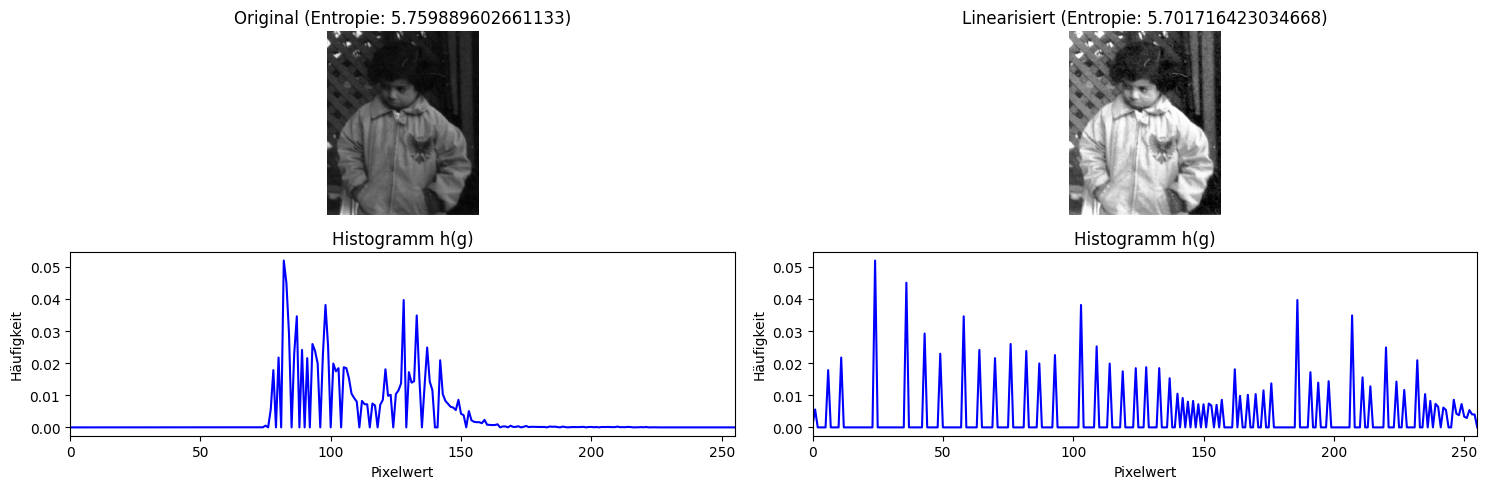

In [160]:
def calculateEntropy(hist_norm):
    hist_norm = hist_norm[hist_norm>0]
    return -np.sum(hist_norm*np.log2(hist_norm))

# Entropie Grauwertbild
entropy = calculateEntropy(hist_norm)

# Histogrammlinearisierung
img_eq = (255*hist_cumu)[img]
hist_eq = cv2.calcHist([img_eq],[0],None,[256],[0,256])
cv2.normalize(hist_eq,hist_eq,norm_type=cv2.NORM_L1)
hist_eq_norm = hist_eq
entropy_eq = calculateEntropy(hist_eq_norm)

# Anzeigen
fig, axes = plt.subplots(2, 2, figsize=(15, 5))

axes[0, 0].imshow(img, cmap='gray')
axes[0, 0].axis('off')
axes[0, 0].set_title(f'Original (Entropie: {entropy})')

axes[1, 0].plot(hist, color='blue')
axes[1, 0].set_xlim([0, 255])
axes[1, 0].set_title('Histogramm h(g)')
axes[1, 0].set_xlabel('Pixelwert')
axes[1, 0].set_ylabel('Häufigkeit')

axes[0, 1].imshow(img_eq, cmap='gray')
axes[0, 1].axis('off')
axes[0, 1].set_title(f'Linearisiert (Entropie: {entropy_eq})')

axes[1, 1].plot(hist_eq, color='blue')
axes[1, 1].set_xlim([0, 255])
axes[1, 1].set_title('Histogramm h(g)')
axes[1, 1].set_xlabel('Pixelwert')
axes[1, 1].set_ylabel('Häufigkeit')

plt.tight_layout()
plt.show()

#### Teil 3: Filter im Ortsraum

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 3.1:</b><br>
  • Importieren Sie <code>coins.png</code> als <b>Grauwertbild</b>.<br>
  • Zeigen Sie das Bild richtig im Jupyter-Notebook an.<br>
  • Geben Sie die Höhe und Breite des Bildes in Pixeln an.<br>
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Überprüfen Sie das Format und die Kanäle, in denen das Bild eingelesen wird, sollte das Bild nicht richtig aussehen.<br>
</div>

(246, 300)


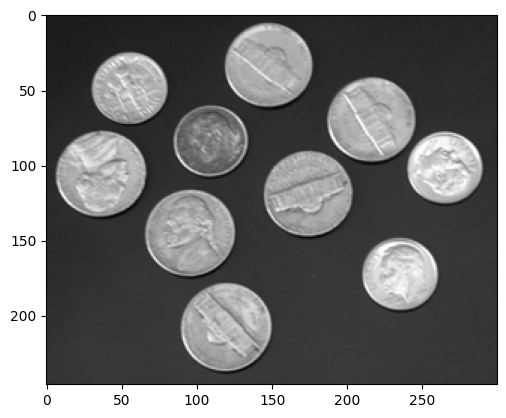

In [161]:
# Bild importieren
img = cv2.imread("coins.png", cv2.IMREAD_GRAYSCALE)
# Bild anzeigen
plt.imshow(img, cmap="grey")

# Dimensionen zeigen
print(img.shape)

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 3.2:</b><br>
  • Implementieren Sie eine Faltungsfunktion auf Grauwertbildern entsprechend der Vorlesung.<br>Es ist Ihnen dabei überlassen, wie Sie das Randproblem lösen (Zeroing, Padding, Clamping, etc.).<br>
  • Wenden Sie die beiden unten stehenden Glättungsfilter auf das eingelesene Bild an und geben Sie die Ergebnisbilder aus.<br>
</div>

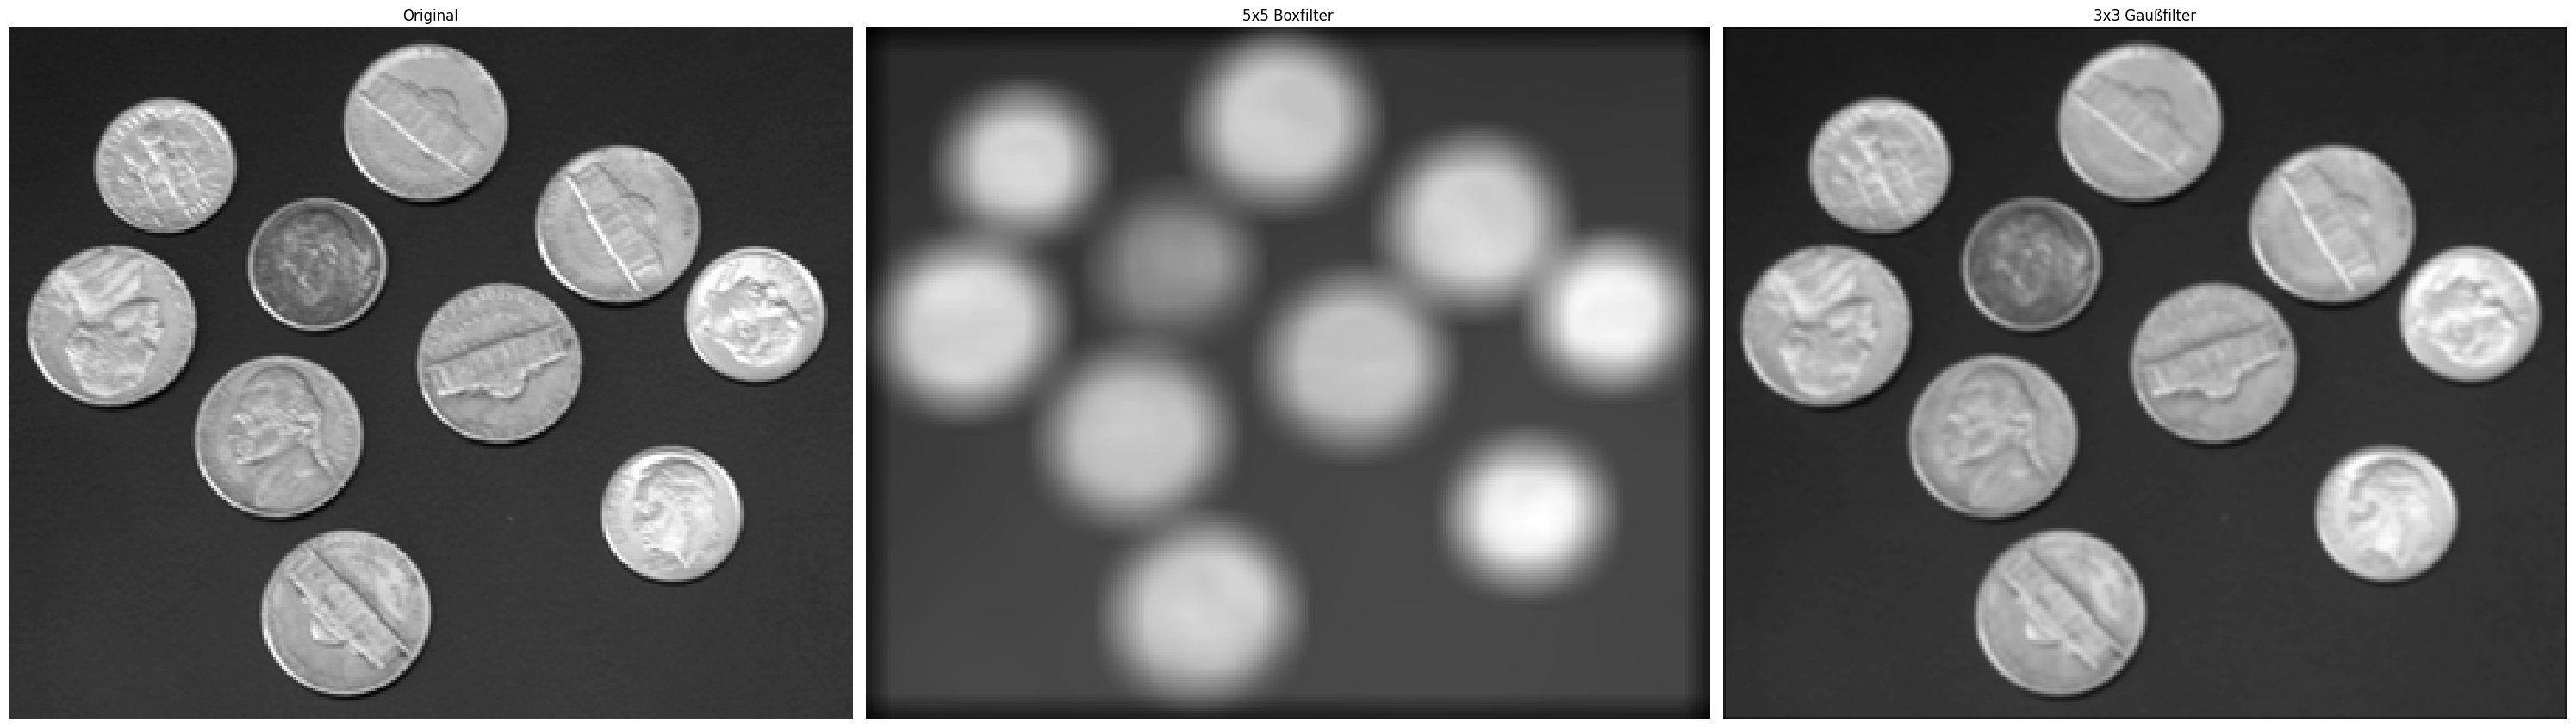

In [ ]:
# Faltungsfunktion
def convolution(img_gray, kernel):
    img_gray = img_gray.astype(np.float64)
    kernel_height,kernel_width = kernel.shape
    padding_top_bot = int((kernel_height - 1) / 2)
    padding_side = int((kernel_width-1) / 2)
    img_height,img_width = img_gray.shape
    new_img = np.array(img_gray)
    for _ in range(padding_side):
        img_gray = np.append(img_gray, np.zeros((img_gray.shape[0],1)),axis=1)
        img_gray = np.insert(img_gray, 0,0,axis=1)
    for _ in range(padding_top_bot):
        img_gray = np.insert(img_gray, 0,0,axis=0)
        img_gray = np.append(img_gray,np.zeros((1,img_gray.shape[1])),axis=0)
    for i in range(img_height):
        for j in range(img_width):
            new_value = 0
            for k in range(-padding_side,padding_side+1):
                for n in range(-padding_side,padding_side+1):
                    new_value = new_value + kernel[k+padding_top_bot][n+padding_side]*img_gray[i+padding_top_bot+k][j+padding_side+n]
            new_img[i][j] = new_value
    return new_img


# 5x5 Boxfilter-Kernel
h_box = 1/25 * np.ones((5,5))
# 3x3 Gaußfilter
h_gaussian = 1/16 * np.array([[1, 2, 1],
                              [2, 4, 2],
                              [1, 2, 1]])

# Filter anwenden
img_conv_boxfilter = convolution(img, h_box)
img_conv_gaussian = convolution(img, h_gaussian) 
# Anzeigen
fig, axes = plt.subplots(1, 3, figsize=(30, 10))

axes[0].imshow(img, cmap='gray')
axes[0].axis('off')
axes[0].set_title('Original')

axes[1].imshow(img_conv_boxfilter, cmap='gray')
axes[1].axis('off')
axes[1].set_title('5x5 Boxfilter')

axes[2].imshow(img_conv_gaussian, cmap='gray')
axes[2].axis('off')
axes[2].set_title('3x3 Gaußfilter')

plt.tight_layout()
plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 3.3:</b><br>
  • Implementieren Sie ohne das Nutzen von OpenCV und ohne die Größe des Originalbildes zu verändern einen Mosaikfilter,<br>welcher für eine variable quadratische Blockgröße (Standardwert: 8x8) den Median nutzt.<br>
  • Wenden Sie den Filter auf das eingelesene Bild an und geben Sie die Ergebnisbilder aus.<br>
</div>

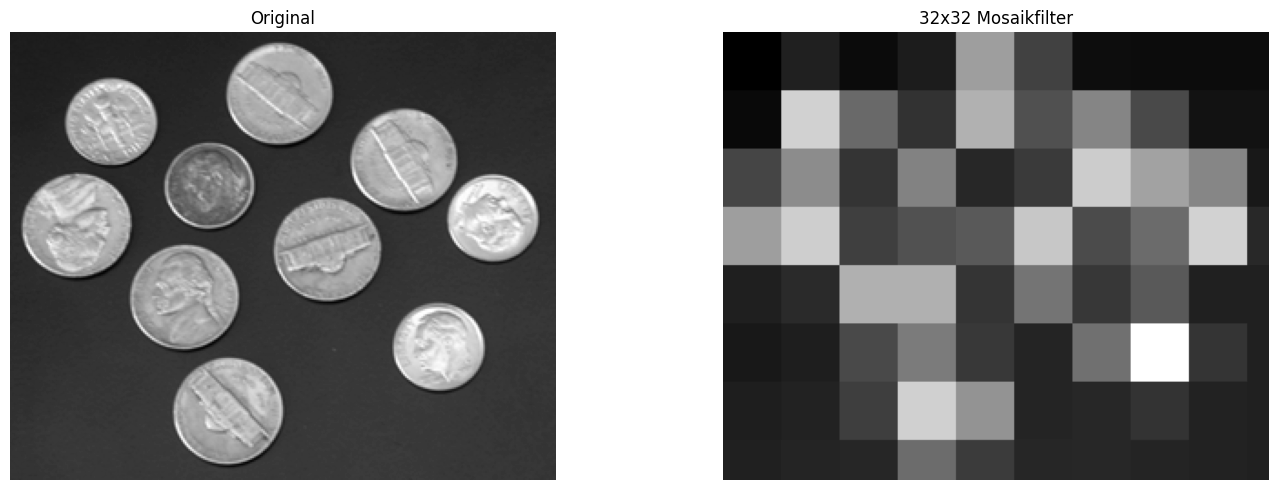

In [177]:
import math

def mosaic_median_filter(img_gray, block_size=8):
    img_gray = img_gray.astype(np.float64)
    new_img = np.array(img_gray)              # nach der Umwandlung kopieren -> float
    height, width = img_gray.shape

    for i in range(math.ceil(height / block_size)):        # inkl. angefangener Blöcke
        for j in range(math.ceil(width / block_size)):
            # Blockgrenzen, am Rand gekappt
            k_end = min((i + 1) * block_size, height)
            n_end = min((j + 1) * block_size, width)

            total = 0
            count = 0
            for k in range(i * block_size, k_end):
                for n in range(j * block_size, n_end):
                    total = total + img_gray[k][n]
                    count = count + 1

            mean = total / count                # tatsächliche Pixelanzahl des Blocks
            for k in range(i * block_size, k_end):
                for n in range(j * block_size, n_end):
                    new_img[k][n] = mean
    return new_img
# Filter anwenden
block_size = 32
img_mosaic = mosaic_median_filter(img, block_size)

# Anzeigen
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].imshow(img, cmap='gray')
axes[0].axis('off')
axes[0].set_title('Original')

axes[1].imshow(img_mosaic, cmap='gray')
axes[1].axis('off')
axes[1].set_title(f'{block_size}x{block_size} Mosaikfilter')

plt.tight_layout()
plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 3.4:</b><br>
  • Im Zuge neuronaler Netzwerke ist es wichtig, Objekte durch ihre Form vom Hintergrund zu unterscheiden und Merkmale hervorzuheben.<br>Überlegen Sie, wie die Kanten der sich auf einem Bild befindenden Objekte mit Hilfe <b>einer einzigen OpenCV-Funktion</b> herausgefunden werden können.<br>
  • Wenden Sie dies auf das Bild an und geben Sie die Ergebnisbilder aus.<br>
</div>

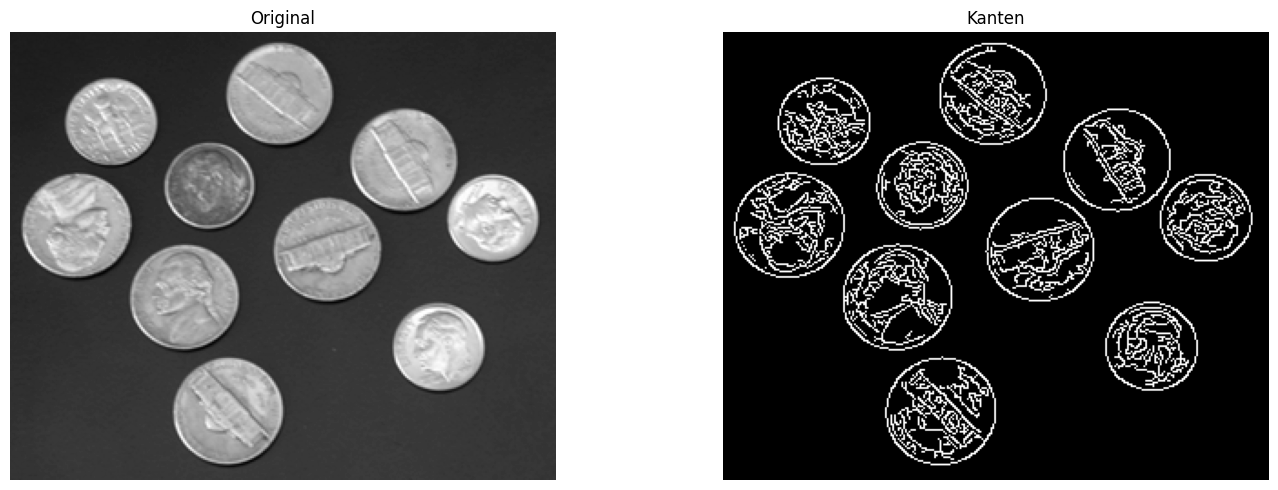

In [189]:
# ???
img_edges = cv2.Canny(img,0,255)

# Anzeigen
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].imshow(img, cmap='gray')
axes[0].axis('off')
axes[0].set_title('Original')

axes[1].imshow(img_edges, cmap='gray')
axes[1].axis('off')
axes[1].set_title(f'Kanten')

plt.tight_layout()
plt.show()